# Proyecto: tu API, tus preguntas

Hoy trabajas solo. Elige una API del menú, trae sus datos a una tabla y hazles preguntas, como hicimos el otro día con Star Wars. Al final lo enseñas en 2 minutos.

Debajo de cada "Ahora tú" va tu código, y cada uno es una cosa pequeña. Cuando termines un paso entero, ponlo en el chat (por ejemplo, "paso 3 listo"). Para ir bien de tiempo, intenta llegar al descanso con el paso 5 hecho.

Antes de empezar, comprueba que arriba a la derecha está elegido el kernel .venv y ejecuta la celda de abajo.

In [39]:
import pandas as pd
import requests

print("Todo listo")

Todo listo


## 0. Elige tu API

Hay cuatro y ninguna la hemos usado en clase. Van de la más fácil a la más difícil. Si no sabes cuál coger, la A.

### A. Planetas fuera del sistema solar (NASA). La recomendada

Es la más sencilla porque llega una lista de diccionarios, igual que en Star Wars. Son todos los planetas que se conocen fuera del sistema solar, más de 6.000, y tarda unos segundos en llegar.

```python
url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+pl_name,hostname,disc_year,discoverymethod,pl_orbper,pl_rade,pl_bmasse,sy_dist+from+pscomppars&format=json"
planetas = requests.get(url).json()
tabla = pd.DataFrame(planetas)
```

El nombre está en pl_name, el año del descubrimiento en disc_year y la forma en que se descubrió en discoverymethod. El tamaño (pl_rade) y la masa (pl_bmasse) van comparados con la Tierra, que vale 1, y la distancia (sy_dist) en pársecs, que son unos 3,3 años luz cada uno.

Documentación: https://exoplanetarchive.ipac.caltech.edu/docs/API_PS_columns.html

### B. Libros de lo que tú quieras (Open Library)

Te devuelve 100 libros del tema que pongas. Si el tema tiene espacios, ponlos con +, por ejemplo harry+potter o cocina+italiana.

```python
tema = "harry+potter"
url = "https://openlibrary.org/search.json?q=" + tema + "&limit=100&fields=title,author_name,first_publish_year,number_of_pages_median,edition_count,ratings_average"
datos = requests.get(url).json()
libros = datos["docs"]
tabla = pd.DataFrame(libros)
```

Ojo, la lista viene dentro de la clave docs. El título está en title, el año en first_publish_year, las páginas en number_of_pages_median, las ediciones en edition_count y la nota (de 0 a 5) en ratings_average.

Documentación: https://openlibrary.org/dev/docs/api/search

### C. Series de TV (TVMaze)

240 series con su nota, lo que dura cada capítulo, su país y si siguen en emisión.

```python
url = "https://api.tvmaze.com/shows?page=0"
series = requests.get(url).json()
tabla = pd.json_normalize(series)
```

Algunos datos vienen dentro de otro diccionario, y json_normalize los saca a columnas normales. El nombre está en name, la nota (de 0 a 10) en rating.average, los minutos en runtime, el país en network.country.name y si sigue o no en status. Si quieres otras 240 series, cambia el 0 de page por un 1.

Documentación: https://www.tvmaze.com/api

### D. Terremotos del último mes (USGS)

La más difícil. Son todos los terremotos de magnitud 4,5 o más del último mes, unos 600.

```python
url = "https://earthquake.usgs.gov/earthquakes/feed/v1.0/summary/4.5_month.geojson"
datos = requests.get(url).json()
tabla = pd.json_normalize(datos["features"])
tabla["longitud"] = tabla["geometry.coordinates"].str[0]
tabla["latitud"] = tabla["geometry.coordinates"].str[1]
tabla["profundidad"] = tabla["geometry.coordinates"].str[2]
```

Aquí la lista está dentro de features y json_normalize saca a columnas lo que viene dentro de cada terremoto. La magnitud queda en properties.mag, el lugar en properties.place y properties.tsunami vale 1 si hubo aviso de tsunami. Las tres últimas líneas separan la longitud, la latitud y la profundidad, que vienen juntas en una lista. Con un gráfico de puntos de longitud y latitud te sale un mapa del mundo.

Documentación: https://earthquake.usgs.gov/earthquakes/feed/v1.0/geojson.php

## 1. Los datos

Ahora tú. Copia el código de tu tarjeta y ejecútalo. Si la API no contesta, vuelve a ejecutar la celda, y si sigue sin ir, elige otra tarjeta.

In [40]:
url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+pl_name,hostname,disc_year,discoverymethod,pl_orbper,pl_rade,pl_bmasse,sy_dist+from+pscomppars&format=json"
planetas = requests.get(url).json()
tabla = pd.DataFrame(planetas)

Antes de mirar la tabla, mira lo que ha llegado. ¿Cuántos elementos tiene la lista? Usa len con la lista de tu tarjeta (planetas, libros, series o datos["features"]).

In [41]:
len(planetas)

6451

Enseña el primer elemento de la lista, como hacíamos con personajes[0]. Es un diccionario, fíjate en sus claves.

In [42]:
planetas[0]

{'pl_name': '55 Cnc b',
 'hostname': '55 Cnc',
 'disc_year': 1996,
 'discoverymethod': 'Radial Velocity',
 'pl_orbper': 14.651552,
 'pl_rade': 13.9,
 'pl_bmasse': 263.9785,
 'sy_dist': 12.5855}

Saca un solo dato de ese primer elemento, con su clave entre corchetes.

In [43]:
planetas[0]["pl_name"]

'55 Cnc b'

## 2. Primer vistazo

Ahora ya con la tabla. En Star Wars salían 87 filas y 36 columnas, una fila por personaje.

Ahora tú. ¿Cuántas filas y columnas tiene tu tabla? Usa print(tabla.shape).

In [44]:
print(tabla.shape)

(6451, 8)


Enseña las primeras filas con tabla.head(). ¿Qué es cada fila en tu tabla?

In [45]:
tabla.head()

,pl_name,hostname,disc_year,discoverymethod,pl_orbper,pl_rade,pl_bmasse,sy_dist
0,55 Cnc b,55 Cnc,1996,Radial Velocity,14.651552,13.900,263.9785,12.5855
1,55 Cnc c,55 Cnc,2004,Radial Velocity,44.393600,8.510,54.4738,12.5855
2,55 Cnc d,55 Cnc,2002,Radial Velocity,4799.000000,13.000,1232.4930,12.5855
3,55 Cnc e,55 Cnc,2004,Radial Velocity,0.736547,1.875,7.9900,12.5855
4,55 Cnc f,55 Cnc,2007,Radial Velocity,260.580000,7.590,44.8120,12.5855


Y las últimas, con tabla.tail().

In [46]:
tabla.tail()

,pl_name,hostname,disc_year,discoverymethod,pl_orbper,pl_rade,pl_bmasse,sy_dist
6446,TOI-426 b,TOI-426,2026,Transit,1.320503,2.190000,6.700000,113.590
6447,TOI-435 b,TOI-435,2026,Transit,3.352919,4.030000,15.300000,165.285
6448,TOI-1873 b,TOI-1873,2026,Transit,7.005727,2.863564,8.570000,182.014
6449,HD 715 b,HD 715,2026,Transit,56.400000,11.993609,201.821038,167.253
6450,TOI-426 c,TOI-426,2026,Radial Velocity,235.800000,13.600000,444.000000,113.590


Enseña los nombres de todas las columnas con tabla.columns.

In [47]:
tabla.columns

Index(['pl_name', 'hostname', 'disc_year', 'discoverymethod', 'pl_orbper',
       'pl_rade', 'pl_bmasse', 'sy_dist'],
      dtype='str')

## 3. Las columnas que te interesan

En Star Wars nos quedamos con seis columnas y les pusimos nombre en español.

```python
tabla = tabla[["id", "name", "height", "mass", "species", "homeworld"]]
tabla.columns = ["id", "nombre", "altura", "peso", "especie", "planeta"]
```

Ahora tú. Quédate con entre 4 y 6 columnas, las que nombra tu tarjeta. Copia los nombres tal cual salen en tabla.columns, con sus puntos si los tienen.

In [48]:
tabla = tabla[["pl_name", "hostname", "disc_year", "discoverymethod", "pl_rade", "sy_dist"]]


Ponles nombres cortos en español, uno por columna y en el mismo orden.

In [49]:
tabla.columns = ["planeta", "estrella", "año", "metodo", "radio", "distancia"]

Guarda la tabla en un CSV con tabla.to_csv("mis_datos.csv", index=False). Así, si después falla la API, no lo pierdes.

In [50]:
tabla.to_csv(r"C:\Users\alvaro\Desktop\Ejercicios Data\mis_datos.csv", index=False)

Léela de vuelta con pd.read_csv y comprueba que tiene las mismas filas.

In [51]:
tabla1 = pd.read_csv("mis_datos.csv")
print(tabla.shape)
print(tabla1.shape)

(6451, 6)
(6451, 6)


## 4. Los huecos

En Star Wars faltaba el peso de 23 personajes.

Ahora tú. Cuenta los huecos de cada columna con tabla.isna().sum().

In [52]:
tabla.isna().sum()

planeta       0
estrella      0
año           0
metodo        0
radio        50
distancia    28
dtype: int64

Enseña las filas a las que les falta el dato de una columna, con tabla[tabla["columna"].isna()]. Pon el nombre de una de tus columnas con huecos.

In [77]:
tabla[tabla["radio"].isna()]

,planeta,estrella,año,metodo,radio,distancia
50,WASP-47 c,WASP-47,2015,Radial Velocity,NaN,264.780000
280,BD+05 4868 A b,BD+05 4868 A,2025,Transit,NaN,43.568700
313,Kepler-93 c,Kepler-93,2014,Radial Velocity,NaN,95.911500
526,HD 160691 b,HD 160691,2000,Radial Velocity,NaN,15.598100
564,HD 179079 b,HD 179079,2008,Radial Velocity,NaN,69.711600
811,HD 7924 b,HD 7924,2008,Radial Velocity,NaN,16.992200
822,KIC 10001893 d,KIC 10001893,2014,Orbital Brightness Modulation,NaN,1672.940000
934,HIP 57274 b,HIP 57274,2011,Radial Velocity,NaN,25.861800
958,BD-06 1339 b,BD-06 1339,2013,Radial Velocity,NaN,20.269500
981,HD 215152 b,HD 215152,2018,Radial Velocity,NaN,21.597400


¿Cuántas filas quedan si quitas todas las que tienen algún hueco? tabla.dropna() las quita, y len cuenta las que quedan. Si a una columna le falta casi todo, mejor no la uses en tus preguntas.

In [54]:
len(tabla.dropna())

6374

## 5. Los números

Ahora tú. Haz tabla.describe(). Saca de cada columna con números cuántos valores hay (count), la media (mean), el mínimo (min) y el máximo (max). En Star Wars la altura iba de 0.66 a 3.9.

In [55]:
tabla.describe()

,año,radio,distancia
count,6451.000000,6401.000000,6423.000000
mean,2017.403038,5.844661,704.833229
std,5.202505,5.400441,1230.179410
min,1992.000000,0.309800,1.301190
25%,2014.000000,1.850000,99.643550
50%,2016.000000,2.860000,349.000000
75%,2021.000000,11.900000,817.261000
max,2026.000000,87.205870,8500.000000


Saca la media de una columna con .mean() y redondéala a 2 decimales con round.

In [56]:
print(round(tabla["radio"].mean(), 2))

5.84


El máximo y el mínimo de esa misma columna, con .max() y .min().

In [57]:
print(tabla["radio"].max())
print(tabla["radio"].min())

87.20586985
0.3098


Lo mismo con otra columna de números: su media, su máximo y su mínimo.

In [58]:
print(round(tabla["año"].mean(), 2))
print(tabla["año"].max())
print(tabla["año"].min())


2017.4
2026
1992


## 6. Lo raro

Si un número se sale mucho de lo normal, mira de quién es. En Star Wars la altura máxima era la de Jabba. No era un error, pero subía la media. Su fila se saca igual que el día más caluroso.

```python
maxima = tabla["altura"].max()
tabla[tabla["altura"] == maxima]
```

Ahora tú. Saca la fila del máximo de una de tus columnas. ¿Es un error o es de verdad?

In [59]:
maximo = tabla["radio"].max()
tabla[tabla["radio"] == maximo]

,planeta,estrella,año,metodo,radio,distancia
400,V2376 Ori b,V2376 Ori,2025,Imaging,87.20587,NaN


Y la fila del mínimo de esa columna.

In [60]:
mínimo = tabla["radio"].min()
tabla[tabla["radio"] == mínimo]

,planeta,estrella,año,metodo,radio,distancia
3736,Kepler-37 b,Kepler-37,2013,Transit,0.3098,63.9207


Elige un número que te parezca muy alto en esa columna y saca las filas que lo pasan, con tabla[tabla["columna"] > numero]. Cuenta cuántas son con len.

In [79]:
len(tabla[tabla["radio"] > 20])

32

## 7. Contar

En una columna de categorías (especie, tipo, año...), value_counts() cuenta cuántas veces sale cada cosa. En Star Wars salían 38 humanos y 6 droides.

```python
tabla["especie"].value_counts()
```

Ahora tú. Cuenta en una columna de categorías de tu tabla.

In [62]:
tabla["año"].value_counts()

año
2016    1504
2014     872
2021     564
2022     367
2026     361
2023     323
2018     308
2024     260
2025     246
2020     234
2019     194
2015     155
2017     152
2012     144
2011     141
2013     128
2010      93
2009      87
2008      62
2007      52
2005      36
2006      32
2002      29
2004      27
2003      22
2000      16
1999      13
2001      12
1996       6
1998       6
1992       2
1995       1
1994       1
1997       1
Name: count, dtype: int64

Quédate solo con los 5 que más salen, poniendo .head(5) al final.

In [63]:
tabla["año"].value_counts().head(5)

año
2016    1504
2014     872
2021     564
2022     367
2026     361
Name: count, dtype: int64

Cuenta en otra columna. Un año también sirve como categoría.

In [64]:
tabla["radio"].value_counts()

radio
12.800000    56
13.300000    55
13.500000    55
13.200000    52
13.400000    51
             ..
2.001000      1
2.451098      1
3.431397      1
3.514187      1
2.863564      1
Name: count, Length: 2304, dtype: int64

## 8. Comparar dos grupos

En Star Wars, los humanos medían 1.79 de media y los droides 1.25. Se filtra cada grupo y se saca su media.

```python
humanos = tabla[tabla["especie"] == "human"]
print("Humanos:", humanos["altura"].mean())
```

Ahora tú. Filtra un primer grupo de tu tabla y guárdalo con un nombre. Cuenta cuántas filas tiene.

In [78]:
transito = tabla[tabla["metodo"] == "Transit"]
len(transito)

4785

Filtra el segundo grupo, el resto. Con != en vez de == te quedas con los que no son.

In [66]:
resto = tabla[tabla["metodo"] != "Transit"]
len(resto)

1666

Compara la media de una columna en los dos grupos, con un print para cada uno.

In [67]:
print("Transito:", transito["radio"].mean())
print("resto:", resto["radio"].mean())

Transito: 4.382198158802257
resto: 10.171452207340757


Haz otra comparación distinta, con otros dos grupos u otra columna.

In [68]:
print("Transito:", transito["distancia"].mean())
print("resto:", resto["distancia"].mean())

Transito: 578.9864632416269
resto: 1067.9845119740955


## 9. Gráficos

En Star Wars, el gráfico de puntos de altura y peso dejaba a Jabba solo en una esquina.

```python
tabla.plot(kind="scatter", x="altura", y="peso")
```

Usa line si algo cambia con el tiempo, bar para comparar cantidades y scatter para ver si dos números van juntos.

Ahora tú. Dibuja en barras uno de los recuentos del paso 7, poniendo .plot(kind="bar") detrás del value_counts().

<Axes: xlabel='metodo'>

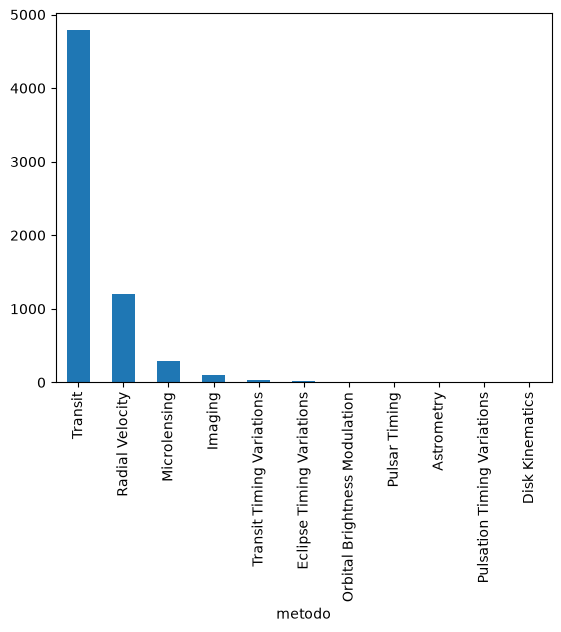

In [69]:
tabla["metodo"].value_counts().plot(kind="bar")

Haz un gráfico de puntos con dos columnas de números.

<Axes: xlabel='distancia', ylabel='radio'>

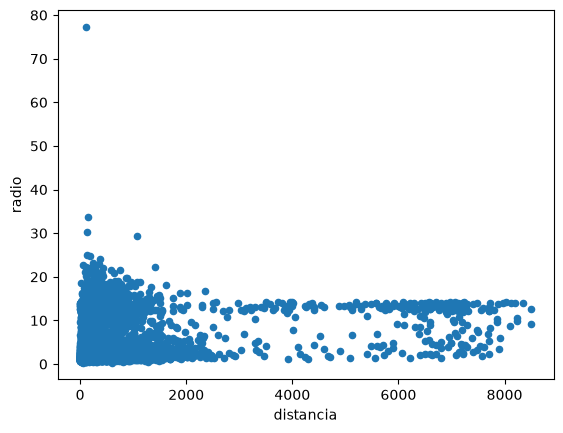

In [70]:
tabla.plot(kind="scatter", x="distancia", y="radio")

Uno más, el que tú quieras. Si tienes una columna de años, tabla["año"].value_counts().sort_index().plot() dibuja cuántos hay cada año.

<Axes: xlabel='año'>

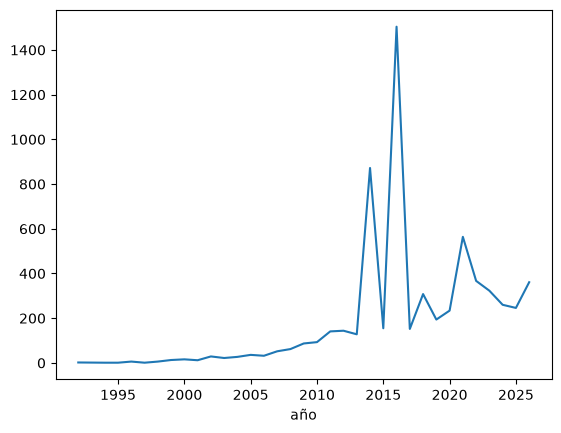

In [71]:
tabla["año"].value_counts().sort_index().plot()

## 10. Tus preguntas

Una pregunta como "¿qué hay en los datos?" no se puede responder. "¿Qué especie tiene más personajes?" sí, con un value_counts. Busca preguntas así, que se contesten con una o dos líneas de código. Te pueden servir estas formas:

- ¿Cuál es el más...? Por ejemplo, el planeta más lejano o la serie con mejor nota.
- ¿Cuántos... hay? Cuántos planetas son del tamaño de la Tierra, cuántos terremotos tuvieron aviso de tsunami.
- ¿Es... mayor en un grupo que en otro? ¿Tienen más nota los libros con más ediciones?

Escribe cada pregunta en la primera línea de su celda, después de un #.

Ahora tú. Una pregunta de "¿cuál es el más...?".

In [72]:
# ¿Cuál es el planeta más cercano a la Tierra?
minima = tabla["distancia"].min()
tabla[tabla["distancia"] == minima]

,planeta,estrella,año,metodo,radio,distancia
1348,Proxima Cen b,Proxima Cen,2016,Radial Velocity,1.020,1.30119
3104,Proxima Cen d,Proxima Cen,2025,Radial Velocity,0.692,1.30119


Una de "¿cuántos... hay?".

In [73]:
# ¿Cuántos planetas se descubrieron desde 2020?
len(tabla[tabla["año"] >= 2020])

2355

Una de "¿es... mayor en un grupo que en otro?".

In [74]:
# ¿Son más grandes que la Tierra los planetas descubiertos?
(tabla["radio"] > 1).value_counts()

radio
True     6162
False     289
Name: count, dtype: int64

Otra pregunta, la que quieras.

In [75]:
# ¿Qué estrella tiene más planetas?
tabla["estrella"].value_counts().head()

estrella
KOI-351       8
TRAPPIST-1    7
HIP 41378     6
TOI-178       6
TOI-1136      6
Name: count, dtype: int64

Y una última.

## 11. Tu conclusión

Haz doble clic en la celda de abajo y escribe en una o dos frases lo que más te ha llamado la atención. Algo como "sin Jabba, el peso medio de los personajes baja 20 kilos".

Escribe aquí tu conclusión.

In [76]:
#Conocemos miles de planetas fuera del sistema solar, la mayoría encontrados por tránsito y gracias al telescopio Kepler. Casi todos son más grandes que la Tierra, pero no porque sean así en general, sino porque los grandes son los más fáciles de encontrar.

## La demo

Tienes 2 minutos para contar qué API has elegido y qué es cada fila, enseñar tu mejor gráfico y leer tu conclusión.

## Si acabas antes

- Añade más preguntas al paso 10.
- Elige otra tarjeta y repite los pasos 1 a 5 con ella.